# 03 · Integración y reducción

**Etapa 03 del pipeline** (transformación). Combina el dataset de home office (15/09/2026) con el de
categorías (13/09/2026) y reduce las columnas redundantes.

| | Archivo |
| --- | --- |
| Entrada | `data/intermedio/02_homeoffice_tratado.csv`, `data/intermedio/01_categorias_limpio.csv` |
| Salida | `data/intermedio/03_homeoffice_integrado.csv`, `data/final/integracion_ofertas_comunes.csv` |

**Técnicas del curso**: integración por la dirección de *agregar atributos*, `merge` y los seis desafíos de
la integración —identificación de entidades, datos sin sentido, formato de índice no coincidente, desajuste de
agregación, objetos duplicados y redundancia— (U3_T4, U3_L6); detección de redundancia con chi-cuadrado y
correlación.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

import comun
from comun import FINAL, INTERMEDIO, escribir_csv, guardar_figura, registrar, registrar_balance, soles

comun.aplicar_estilo()
ho = pd.read_csv(INTERMEDIO / '02_homeoffice_tratado.csv', parse_dates=['fecha_extraccion'],
                 dtype={'id_oferta': 'string', 'id_catalogo': 'string'})
cat = pd.read_csv(INTERMEDIO / '01_categorias_limpio.csv', parse_dates=['fecha_extraccion'],
                  dtype={'id_oferta': 'string'})
N_ENTRADA = len(ho)
print('home office:', ho.shape, '| categorías:', cat.shape)

home office: (2714, 26) | categorías: (4412, 6)


## 1. Identificación de entidades y formato del índice

Para unir dos fuentes hay que saber cuándo dos filas son **la misma entidad**. La Parte I identificó el home
office por código de catálogo y las categorías por oferta: dos formatos de índice distintos para el mismo
objeto. Se compara cuántas coincidencias da cada criterio.

In [2]:
por_catalogo = ho['id_catalogo'].isin(cat['id_oferta'])
por_oferta = ho['id_oferta'].isin(cat['id_oferta'])
claves = pd.DataFrame({'clave de unión': ['catálogo del home office ↔ oferta de categorías (formatos distintos)',
                                          'oferta ↔ oferta (mismo formato)'],
                       'ofertas comunes': [int(por_catalogo.sum()), int(por_oferta.sum())]})
claves

,clave de unión,ofertas comunes
0,catálogo del home office ↔ oferta de categoría...,258
1,oferta ↔ oferta (mismo formato),767


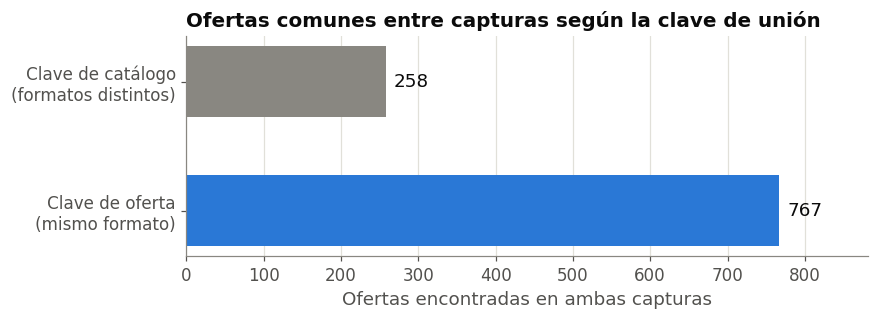

Lectura: Sí, y mucho: unir por código de catálogo encuentra 258 ofertas comunes y unir por oferta encuentra 767, 3.0 veces más. Con la clave de la Parte I, la mayoría de las ofertas repetidas entre capturas habría pasado como distinta.


In [3]:
fig, ax = plt.subplots(figsize=(8, 2.6))
etiquetas = ['Clave de catálogo\n(formatos distintos)', 'Clave de oferta\n(mismo formato)']
ax.barh(etiquetas, claves['ofertas comunes'], color=[comun.TINTA_TENUE, '#2a78d6'], height=0.55)
for y, valor in enumerate(claves['ofertas comunes']):
    ax.text(valor + 10, y, f'{valor}', va='center', color=comun.TINTA)
ax.set(title='Ofertas comunes entre capturas según la clave de unión', xlabel='Ofertas encontradas en ambas capturas')
ax.set_xlim(0, claves['ofertas comunes'].max() * 1.15)
ax.grid(axis='y', visible=False)
ax.invert_yaxis()
guardar_figura(fig, 'f03_clave_de_union',
               '¿Cambia el resultado de la integración según el identificador usado?',
               f'Sí, y mucho: unir por código de catálogo encuentra {claves.iloc[0, 1]} ofertas comunes y unir por '
               f'oferta encuentra {claves.iloc[1, 1]}, {claves.iloc[1, 1] / claves.iloc[0, 1]:.1f} veces más. Con la '
               f'clave de la Parte I, la mayoría de las ofertas repetidas entre capturas habría pasado como distinta.')

## 2. Datos sin sentido y desajuste de agregación

- **Datos sin sentido para esta pregunta**: celulares, televisores y refrigeradoras no son componentes de un
  home office. Solo aportan al análisis las ofertas de categorías que también están en el home office.
- **Desajuste de agregación**: las capturas difieren en fecha (13/09 y 15/09), en páginas por búsqueda (20 y 10)
  y en búsquedas. Por eso no se suman ni se promedian juntas: la integración compara **oferta por oferta**,
  que es la única unidad común a ambas.

Además, se comprueba que una oferta común pertenezca al mismo tipo de producto en las dos capturas.

In [4]:
comunes = ho.loc[por_oferta, ['id_oferta', 'componente', 'titulo', 'precio']].merge(
    cat[['id_oferta', 'busqueda', 'titulo', 'precio', 'fecha_extraccion']].rename(
        columns={'busqueda': 'busqueda_13_09', 'titulo': 'titulo_13_09', 'precio': 'precio_13_09',
                 'fecha_extraccion': 'fecha_13_09'}),
    on='id_oferta', how='inner', validate='one_to_one')
print(pd.crosstab(comunes['componente'], comunes['busqueda_13_09']).to_string())
titulo_igual = (comunes['titulo'].str.lower() == comunes['titulo_13_09'].str.lower()).mean() * 100
print(f'\nTítulo idéntico en ambas capturas: {titulo_igual:.1f} % de las ofertas comunes')

busqueda_13_09  audifonos  laptops
componente                        
audifonos             344        0
laptop                 13      408
monitor                 2        0

Título idéntico en ambas capturas: 98.8 % de las ofertas comunes


Casi todas las ofertas comunes son laptops y audífonos encontrados en sus propias búsquedas, y el título coincide
en casi el 99 % de los casos. La excepción es reveladora: algunas laptops y monitores aparecieron el 13/09 **en la
búsqueda de audífonos**. Son anuncios que el sitio inserta en búsquedas ajenas, el mismo fenómeno que obligó a
reasignar publicaciones en el notebook 01. La búsqueda de origen no define el producto; el título sí, y por eso
el componente se toma del home office, donde ya está corregido.

## 3. Integración por la dirección "agregar atributos"

A cada oferta de home office se le **agrega** su precio del 13/09 y la variación respecto del 15/09
(`merge` por `id_oferta`, U3_L6). Regla ante conflictos: prevalece el home office, que es la captura más
reciente y la que tiene más atributos; del dataset de categorías solo se toma el precio y la fecha.

La dirección **agregar objetos** (sumar como filas nuevas las laptops y los audífonos que solo están en
categorías) se descarta: esas filas no tienen descuento, reseñas ni envío, y pertenecen a otra fecha.

In [5]:
integrado = ho.merge(comunes[['id_oferta', 'precio_13_09']], on='id_oferta', how='left', validate='one_to_one')
integrado['en_ambas_capturas'] = integrado['precio_13_09'].notna()
integrado['variacion_precio_pct'] = ((integrado['precio'] - integrado['precio_13_09'])
                                     / integrado['precio_13_09'] * 100).round(2)

solo_cat = cat.loc[cat['busqueda'].isin(['laptops', 'audifonos']) & ~cat['id_oferta'].isin(ho['id_oferta'])]
grupos = pd.Series({'solo home office': int((~integrado['en_ambas_capturas']).sum()),
                    'en ambas capturas': int(integrado['en_ambas_capturas'].sum()),
                    'solo categorías (laptops y audífonos)': len(solo_cat)}, name='ofertas')
assert grupos['solo home office'] + grupos['en ambas capturas'] == len(ho), 'Los grupos no suman el home office.'
assert len(integrado) == len(ho), 'El merge multiplicó filas: hay duplicados.'
grupos.to_frame()

,ofertas
solo home office,1947
en ambas capturas,767
solo categorías (laptops y audífonos),1120


**Objetos duplicados**: el `merge` se hizo con `validate='one_to_one'`, que falla si una oferta aparece más de
una vez en cualquiera de las dos fuentes; el número de filas no cambió.

In [6]:
var = integrado.loc[integrado['en_ambas_capturas'], ['componente', 'variacion_precio_pct']]
resumen_var = var.groupby('componente')['variacion_precio_pct'].agg(
    ofertas='size', sin_cambio=lambda s: (s.abs() < 0.01).mean() * 100, subieron=lambda s: (s > 0.01).mean() * 100,
    bajaron=lambda s: (s < -0.01).mean() * 100, mediana='median').round(1)
resumen_var

,ofertas,sin_cambio,subieron,bajaron,mediana
componente,,,,,
audifonos,344,75.9,12.5,11.6,0.0
laptop,421,73.9,14.5,11.6,0.0
monitor,2,50.0,50.0,0.0,43.1


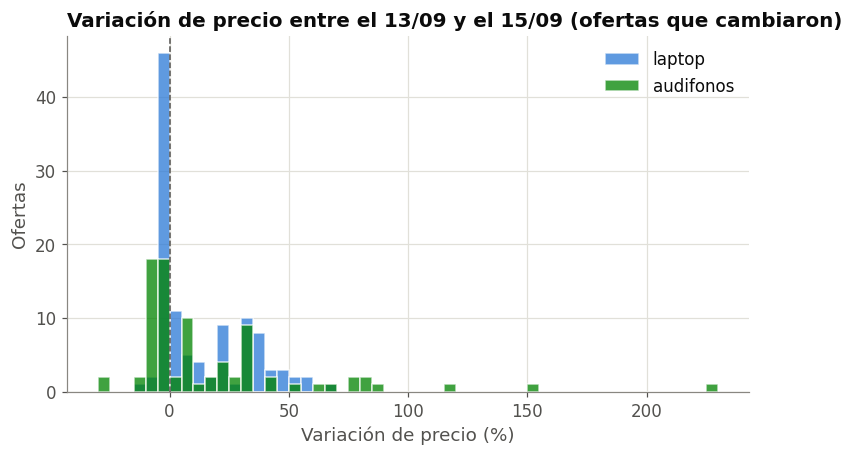

Lectura: De 767 ofertas presentes en ambas capturas, 573 (75 %) mantuvieron exactamente el mismo precio. Entre las que cambiaron dominan las subidas: 105 subieron y 89 bajaron, con una variación mediana de +1.9 %. Un precio de referencia es estable en el corto plazo, pero conviene fecharlo.


In [7]:
fig, ax = plt.subplots(figsize=(8, 4.2))
cambiaron = var[var['variacion_precio_pct'].abs() >= 0.01]
bins = np.arange(np.floor(cambiaron['variacion_precio_pct'].min() / 5) * 5,
                 cambiaron['variacion_precio_pct'].max() + 5, 5)
for componente in ['laptop', 'audifonos']:
    datos = cambiaron.loc[cambiaron['componente'] == componente, 'variacion_precio_pct']
    ax.hist(datos, bins=bins, color=comun.COLOR_COMPONENTE[componente], alpha=0.75, label=componente,
            edgecolor='white', linewidth=1)
ax.axvline(0, color=comun.TINTA_SECUNDARIA, linewidth=1, linestyle='--')
ax.set(title='Variación de precio entre el 13/09 y el 15/09 (ofertas que cambiaron)',
       xlabel='Variación de precio (%)', ylabel='Ofertas')
ax.legend()
total_var = len(var)
sin_cambio = int((var['variacion_precio_pct'].abs() < 0.01).sum())
subieron = int((var['variacion_precio_pct'] > 0.01).sum())
bajaron = int((var['variacion_precio_pct'] < -0.01).sum())
tendencia = ('dominan las subidas' if subieron > bajaron else 'dominan las bajadas' if bajaron > subieron
             else 'subidas y bajadas se equilibran')
guardar_figura(fig, 'f03_variacion_precio',
               '¿Cambian los precios de una misma oferta en dos días?',
               f'De {total_var} ofertas presentes en ambas capturas, {sin_cambio} ({sin_cambio / total_var * 100:.0f} %) '
               f'mantuvieron exactamente el mismo precio. Entre las que cambiaron {tendencia}: {subieron} subieron y '
               f'{bajaron} bajaron, con una variación mediana de {cambiaron["variacion_precio_pct"].median():+.1f} %. Un '
               f'precio de referencia es estable en el corto plazo, pero conviene fecharlo.')

## 4. Redundancia y reducción

El último desafío de la integración es la **redundancia**: columnas que repiten información de otras. Se
evalúa con chi-cuadrado y V de Cramér entre categóricas y con la correlación de Pearson entre numéricas.

In [8]:
def cramer_v(a, b):
    tabla = pd.crosstab(a, b)
    estadistico = chi2_contingency(tabla)[0]
    return np.sqrt(estadistico / (tabla.to_numpy().sum() * (min(tabla.shape) - 1)))


pares_cat = [('busqueda', 'componente'), ('tiene_descuento', 'ofrece_cuotas'), ('vendedor_visible', 'tiene_resenas'),
             ('es_publicidad', 'tiene_descuento'), ('envio', 'componente')]
redundancia_cat = pd.DataFrame([{'par': f'{a} ~ {b}', 'V de Cramér': cramer_v(integrado[a], integrado[b]),
                                 'p': chi2_contingency(pd.crosstab(integrado[a], integrado[b]))[1]}
                                for a, b in pares_cat]).round(4)
pares_num = [('precio', 'monto_cuota'), ('descuento_pct', 'descuento_anunciado_pct'), ('precio', 'precio_anterior'),
             ('calificacion', 'vendidos_min')]
redundancia_num = pd.DataFrame([{'par': f'{a} ~ {b}', 'r de Pearson': integrado[[a, b]].astype(float).corr().iloc[0, 1]}
                                for a, b in pares_num]).round(3)
display(redundancia_cat)
redundancia_num

,par,V de Cramér,p
0,busqueda ~ componente,0.9954,0.000
1,tiene_descuento ~ ofrece_cuotas,0.0387,0.044
2,vendedor_visible ~ tiene_resenas,0.0433,0.024
3,es_publicidad ~ tiene_descuento,0.0063,0.742
4,envio ~ componente,0.3228,0.000


,par,r de Pearson
0,precio ~ monto_cuota,0.937
1,descuento_pct ~ descuento_anunciado_pct,0.994
2,precio ~ precio_anterior,0.989
3,calificacion ~ vendidos_min,0.037


Decisiones:

| Columna | Evidencia | Decisión |
| --- | --- | --- |
| `busqueda` | V de Cramér ≈ 1 con `componente`; solo difieren las ofertas reasignadas, ya registradas en `data/evidencia/01_reasignadas.csv` | **se retira** |
| `descuento_anunciado_pct` | r ≈ 1 con el descuento calculado, pero difieren en las inconsistencias detectadas | se conserva: permite medir descuentos anunciados que no coinciden con el real |
| `monto_cuota` | r alto con el precio (es el precio dividido entre las cuotas sin interés) | se conserva: es la cifra que el usuario paga cada mes |
| `precio_anterior` | r alto con el precio | se conserva: es la base del descuento |

Las demás asociaciones son moderadas o débiles: no hay redundancia que justifique retirar otras columnas.

In [9]:
reducido = integrado.drop(columns='busqueda')
assert reducido['id_oferta'].is_unique
assert (reducido['precio_13_09'].notna() == reducido['en_ambas_capturas']).all(), \
    '`precio_13_09` solo existe si `en_ambas_capturas`'
registrar_balance('03_homeoffice', N_ENTRADA, len(reducido))
escribir_csv(reducido, INTERMEDIO / '03_homeoffice_integrado.csv')

ofertas_comunes = (reducido.loc[reducido['en_ambas_capturas'],
                                ['id_oferta', 'componente', 'precio_13_09', 'precio', 'variacion_precio_pct']]
                   .rename(columns={'precio': 'precio_15_09'}).sort_values('id_oferta'))
escribir_csv(ofertas_comunes, FINAL / 'integracion_ofertas_comunes.csv')

registrar('integracion', comunes_por_catalogo=int(por_catalogo.sum()), comunes_por_oferta=int(por_oferta.sum()),
          solo_home_office=int(grupos['solo home office']), solo_categorias_mismas_busquedas=len(solo_cat),
          sin_cambio_pct=sin_cambio / total_var * 100, subieron=subieron,
          bajaron=bajaron, titulo_identico_pct=titulo_igual,
          variacion_mediana_cambiaron=cambiaron['variacion_precio_pct'].median(),
          columnas_retiradas=['busqueda'])
print('03_homeoffice_integrado.csv:', reducido.shape, '| ofertas comunes:', len(ofertas_comunes))

03_homeoffice_integrado.csv: (2714, 28) | ofertas comunes: 767


## Resultado de la etapa

- Con la misma clave de oferta en ambas fuentes, la integración encuentra muchas más ofertas comunes que con la
  clave de catálogo de la Parte I.
- Se agregaron atributos (precio del 13/09 y variación) sin multiplicar filas; la dirección de agregar objetos
  se descartó con justificación.
- Se revisaron los seis desafíos de la integración y se retiró la única columna redundante.